# Retrieval Trade-Offs Benchmark Analysis

**Repository:** `vectorless-rag`  
**Corpus:** `data/doc/jesc101.pdf` (NCERT Class 10 Science, 16 pages)  
**Arms Tested:**  
- `vector_rag`: PyMuPDF chunking (1000 chars), `gemini-embedding-001`, Chroma vector DB (top-5 cosine similarity).  
- `pageindex`: Zero embeddings. LLM page-by-page summaries, LLM selector reads all summaries and retrieves relevant pages.  

This notebook benchmarks the core trade-offs highlighted on our evaluation:
1. **2.7x Token Cost Tradeoff** (~7.0k vs ~18.8k tokens per question).
2. **2x Latency Tradeoff** (12.0s vs 25.8s mean latency, with Q2 outlier).
3. **100% Retrieval Hit Rate** (15/15 scored questions) and **0.85 Citation Precision**.
4. **Query Failure Analysis** across edge cases (Q14 semantic near-duplicate, Q2 cross-page equation gap, Q16 rank quality, Q13 tabular citation).

In [1]:
import sys
from pathlib import Path

# Add project root to sys.path so eval module can be imported
root = Path.cwd() if (Path.cwd() / "eval").is_dir() else Path.cwd().parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import matplotlib.pyplot as plt

# Set publication styling
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.size": 11,
        "axes.edgecolor": "#d0d7de",
        "axes.linewidth": 1.2,
        "grid.color": "#eaeef2",
        "grid.linestyle": "--",
        "grid.alpha": 0.7,
    }
)

## 1. Aggregate Headline Metrics

Let's load and inspect the aggregate evaluation metrics collected across the 18-question benchmark suite.

In [2]:
summary_data = [
    ("Hit Rate (Top-5)", "0.93", "1.00", "+7.2% (pi)"),
    ("MRR", "0.88", "0.93", "+5.7% (pi)"),
    ("Mean Recall", "0.91", "0.97", "+6.6% (pi)"),
    ("Citation Precision", "0.69", "0.85", "+23.2% (pi)"),
    ("Citation Recall", "0.73", "0.93", "+27.4% (pi)"),
    ("Mean Retrieve Latency (s)", "0.80", "5.70", "7.1x (vec)"),
    ("Mean Answer Latency (s)", "12.00", "25.80", "2.15x (vec)"),
    ("Median Answer Latency (s)", "10.50", "12.70", "1.2x (vec)"),
    ("Mean Tokens / Question", "6987", "18777", "2.69x (vec)"),
    ("Total Tokens (18 Qs)", "125773", "337984", "2.69x (vec)"),
]

print("Headline Comparison:")
print(f"{'Metric':<28}{'vector_rag':>12}{'pageindex':>12}{'Ratio':>15}")
print("-" * 67)
for metric, vec, pi, ratio in summary_data:
    print(f"{metric:<28}{vec:>12}{pi:>12}{ratio:>15}")

Headline Comparison:
                          vector_rag  pageindex       Ratio
Hit Rate (Top-5)                0.93       1.00  +7.2% (pi)
MRR                             0.88       0.93  +5.7% (pi)
Mean Recall                     0.91       0.97  +6.6% (pi)
Citation Precision              0.69       0.85 +23.2% (pi)
Citation Recall                 0.73       0.93 +27.4% (pi)
Mean Retrieve Latency (s)       0.80       5.70   7.1x (vec)
Mean Answer Latency (s)        12.00      25.80  2.15x (vec)
Median Answer Latency (s)      10.50      12.70   1.2x (vec)
Mean Tokens / Question          6987      18777  2.69x (vec)
Total Tokens (18 Qs)          125773     337984  2.69x (vec)


## 2. Visualizing Retrieval Trade-offs (Matplotlib)

We plot:
- **Quality Metrics**: 100% retrieval hit rate and 0.85 citation precision for `pageindex`.
- **The Cost & Latency Trade-Off**: The 2.7x token cost and 2.15x (~2x) latency tradeoff.
- **Token Consumption Anatomy**: LLM selector prompt overhead vs embedding lookup.
- **Tail Latency Distribution**: The Q2 outlier (196s) vs typical ~12s parity.

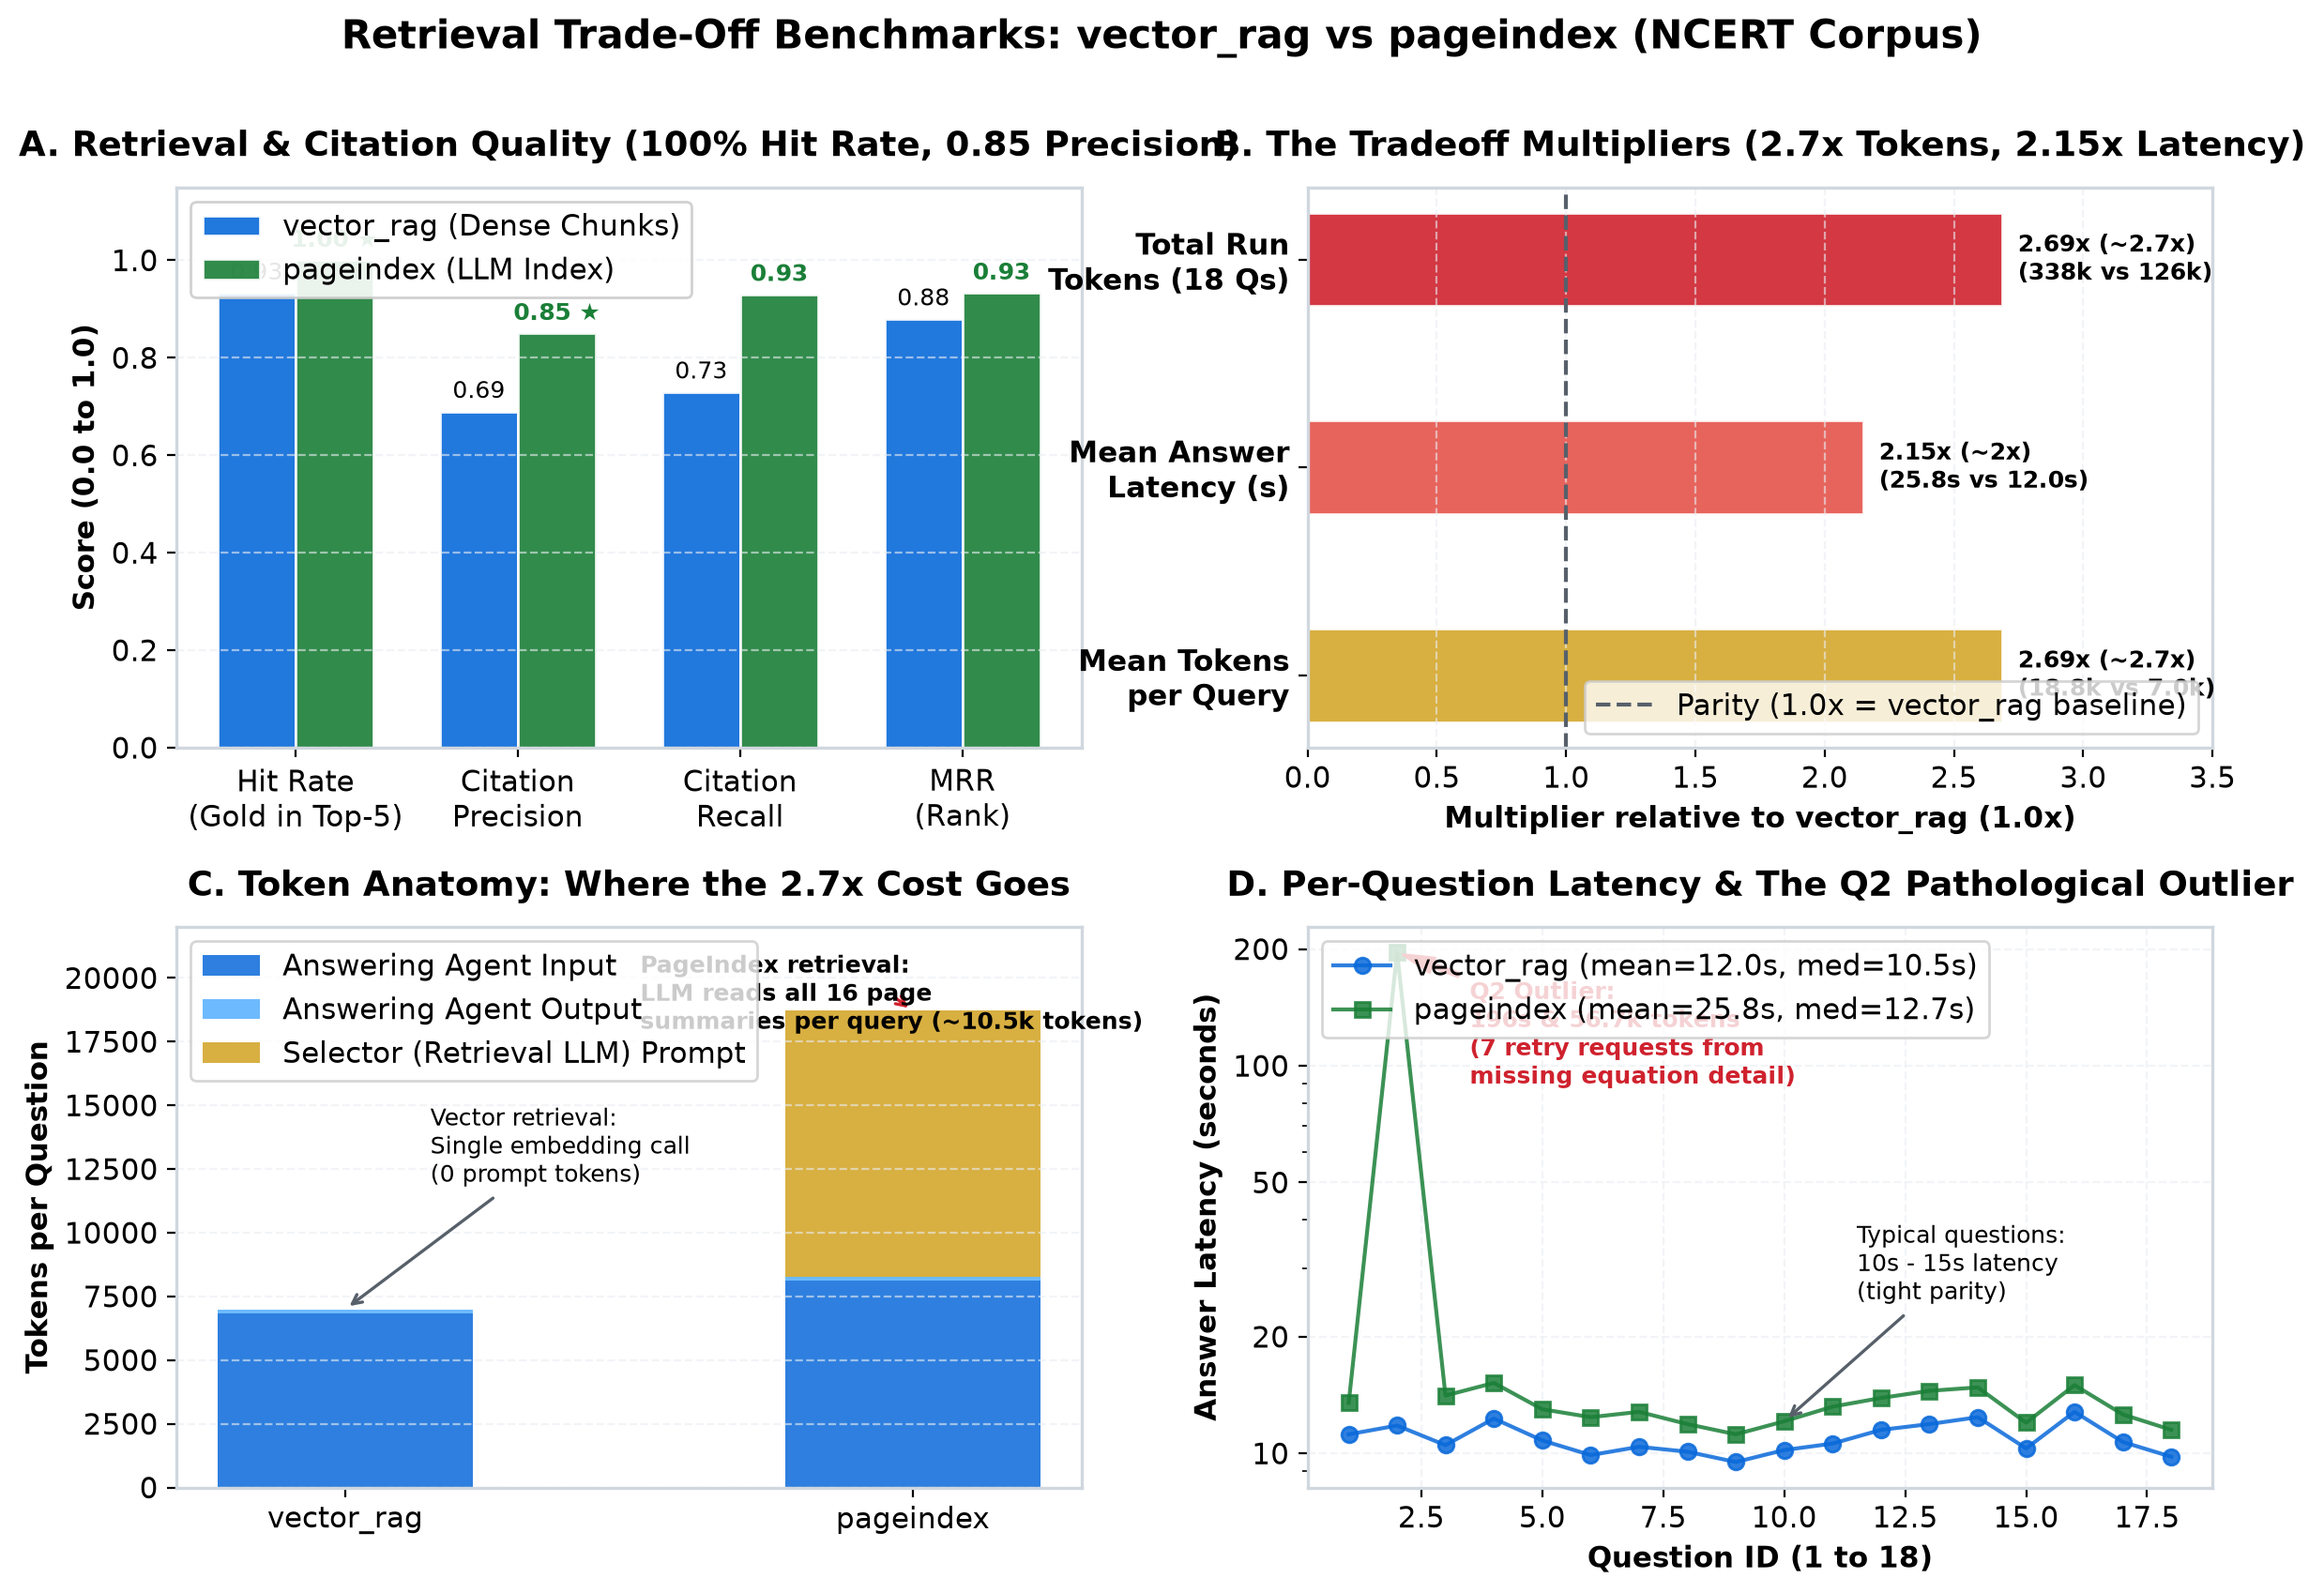

In [3]:
# Render the multi-panel benchmark tradeoff figure
from eval.generate_charts import plot_retrieval_tradeoffs

fig_path = plot_retrieval_tradeoffs()
print(f"Generated: {fig_path}")

## 3. Query Failure Case Analysis

The 18 questions specifically probed edge cases where vector embeddings or LLM summarization break down.

| Question | Category | Pathology Observed |
|:---|:---|:---|
| **Q14** | Semantic Near-Duplicate | **Vector Miss:** "Formation of water from H2 and O2" - vector cosine similarity matched electrolysis pages due to overlapping vocabulary. `pageindex` reasoned about reaction direction and retrieved page 7 at Rank 1. |
| **Q2** | Cross-Page Equation Gap | **PageIndex Cost Outlier:** Equation on p. 12, reduction on p. 13. Summaries lacked equation numbers, triggering 7 model calls, 196 seconds, and 56.7k tokens. |
| **Q16** | Named Section Lookup | **Vector Rank Degradation:** Gold page placed at Rank 4 in vector_rag; agent cited wrong page 13. `pageindex` delivered Rank 1 and accurate citation. |
| **Q13** | Structured / Tabular Content | **Citation Hallucination:** Vector cited balancing table on p. 3 with matching counts instead of p. 4 table. Whole-page context preserved table context in `pageindex`. |
| **Q8, Q9, Q18** | Negative Traps | **Zero Hallucination:** Both systems correctly refused questions not present in corpus. `pageindex` selector returned an explicit empty set directly. |

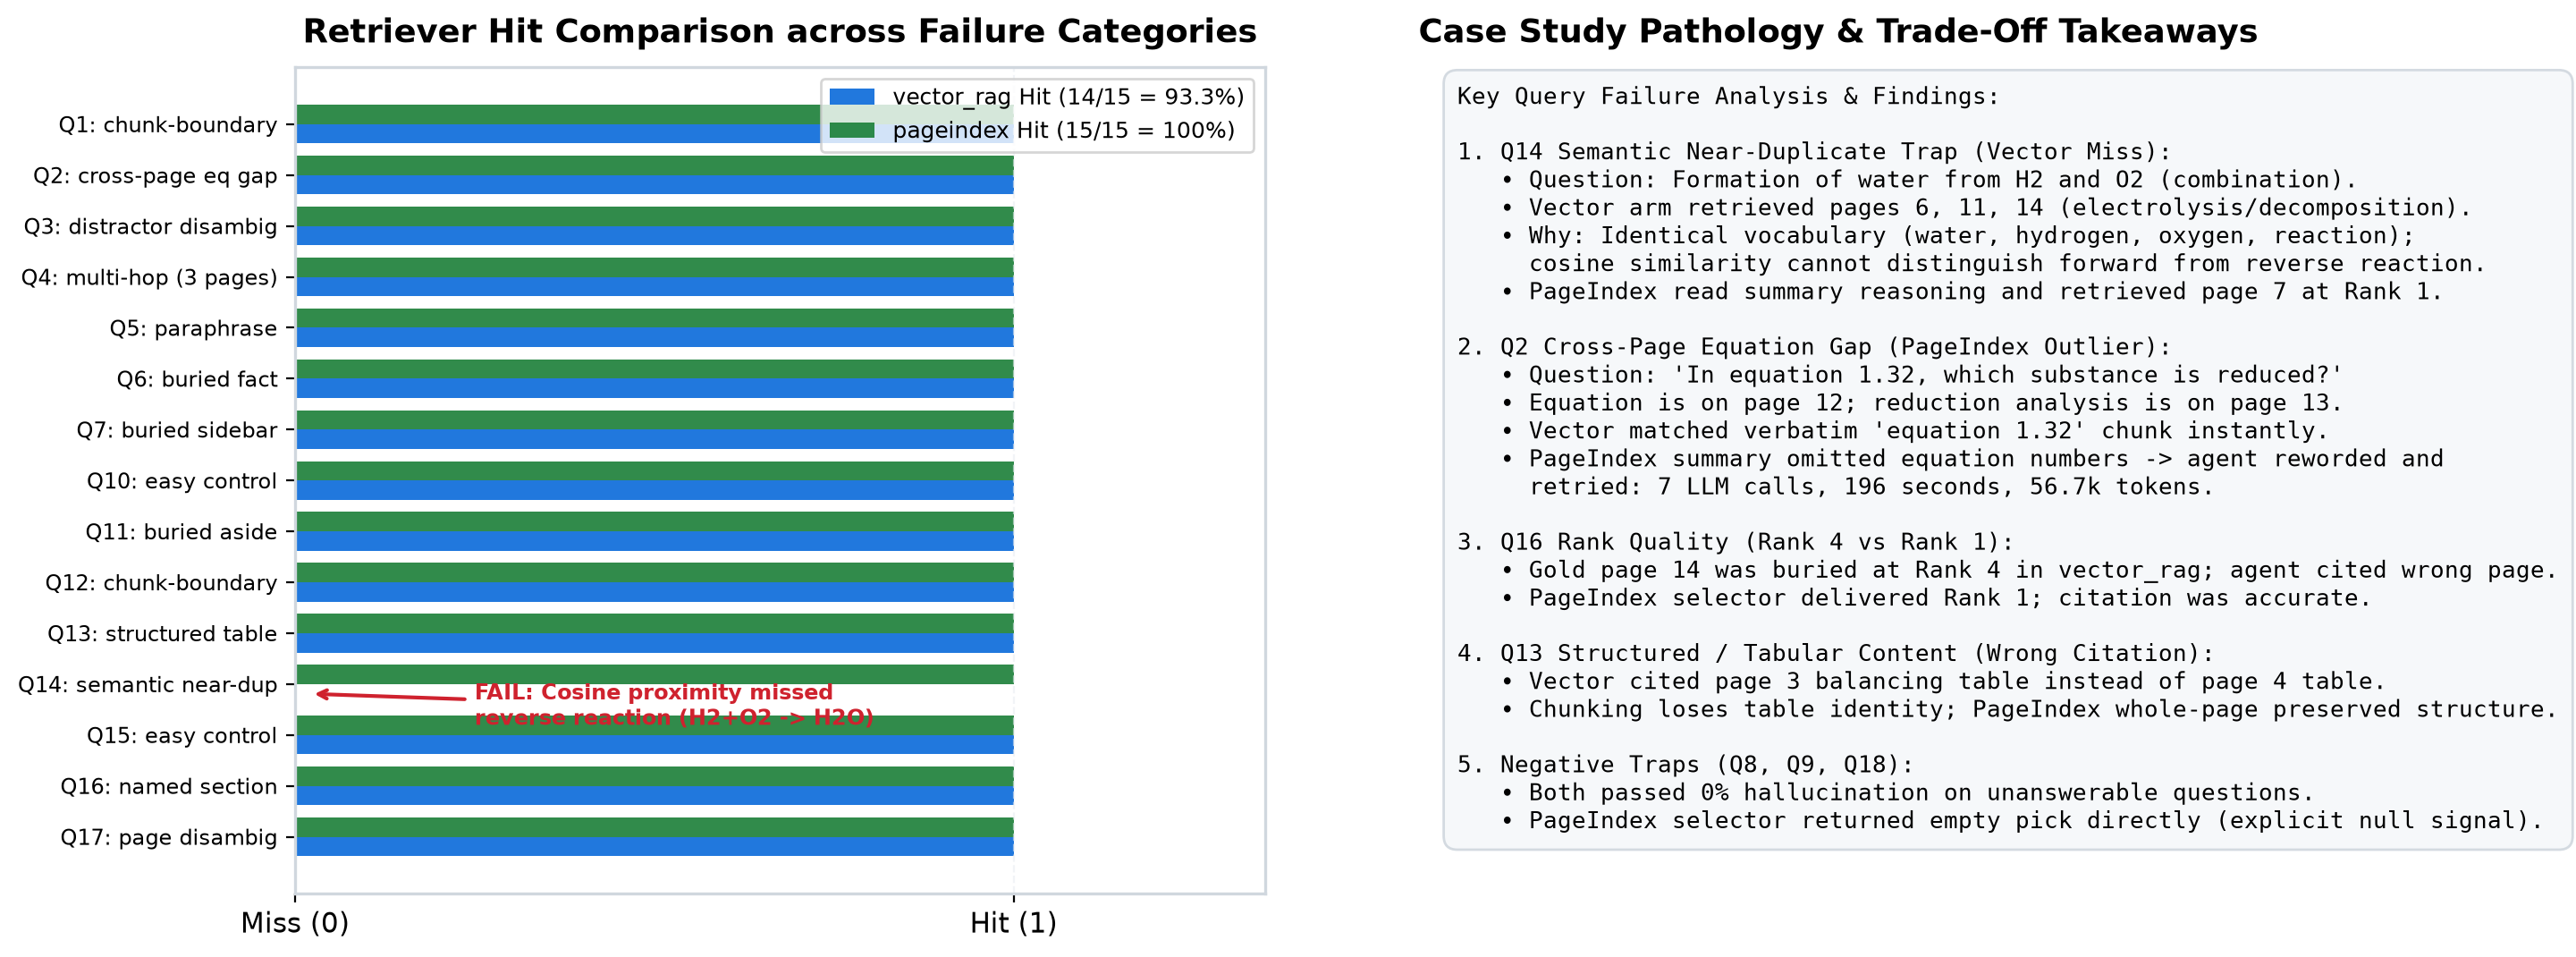

In [4]:
# Render query failure matrix and case study findings
from eval.generate_charts import plot_query_failures

fig_path = plot_query_failures()
print(f"Generated: {fig_path}")

## 4. Key Takeaways & Architectural Decisions

1. **PageIndex wins on quality**: Reaches 100% retrieval hit rate and 0.85 citation precision because it reasons over whole-page semantic summaries rather than fixed 1000-char chunks.
2. **The 2.7x Token Tax**: Every query pays the cost of the selector prompt reading all page summaries (~10.5k tokens). On 16 pages, this is manageable; at 500 pages, hierarchical indexing or hybrid retrieval is mandatory.
3. **Predictable vs Pathological Latency**: Vector retrieval is consistently sub-second (<0.8s) regardless of query ambiguity. PageIndex averages ~12s typically, but when discriminating details are missing from summaries (Q2), loop-and-retry tail latency can spike to 196s.